# Partie 3 : Création d'un transformateur personnalisé

**Cours :** 030513 IFM, Intelligence artificielle appliquée au prétraitement des données (automne 2026)

**Évaluation sommative 2 :** Création des pipelines (Prof. Nadjate Saïdani)

**Équipe :**
- Akiella Wankoua, Blonde Béatrice
- Essomba, Martin Junior
- Gouater, Rene Eutyche
- Misse, Anthony

**But du notebook :** créer nos propres classes de transformation avec `TransformerMixin` et les ajouter au pipeline de prétraitement.

**Ce que le notebook utilise :**
- `donnees/preparees/` (notebook 01)
- `modeles/etape2_pretraitement.joblib` : groupes de colonnes et pipelines (notebook 02)

**Ce que le notebook produit pour la suite :**
- `notebooks/transformateurs.py` : nos classes (importées par les notebooks 04 et 05)
- `modeles/etape3_pipeline_pretraitement.joblib` : le pipeline de prétraitement complet (lu par le notebook 04)
- `figures/03_plafonnement_adr.png` (pour les diapositives)

## Importation des librairies

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

DOSSIER_PREPAREES = Path("../donnees/preparees")
DOSSIER_MODELES = Path("../modeles")
DOSSIER_FIGURES = Path("../figures")

## Chargement des résultats des notebooks 01 et 02

In [2]:
X_train = pd.read_csv(DOSSIER_PREPAREES / "X_train.csv", dtype={"agent": str})
X_test = pd.read_csv(DOSSIER_PREPAREES / "X_test.csv", dtype={"agent": str})
y_train = pd.read_csv(DOSSIER_PREPAREES / "y_train.csv")["is_canceled"]
y_test = pd.read_csv(DOSSIER_PREPAREES / "y_test.csv")["is_canceled"]

etape2 = joblib.load(DOSSIER_MODELES / "etape2_pretraitement.joblib")
groupes = etape2["groupes"]
pipelines = etape2["pipelines"]

print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Groupes récupérés du notebook 02 :", list(groupes.keys()))
print("Pipelines récupérés du notebook 02 :", list(pipelines.keys()))

X_train : (69783, 27) | X_test : (17446, 27)
Groupes récupérés du notebook 02 : ['num_asym', 'num', 'bin', 'cat_faible', 'cat_forte']
Pipelines récupérés du notebook 02 : ['num_asym', 'num', 'cat_faible', 'cat_forte']


**Ce qu'on observe :**

- On retrouve les données du notebook 01 (69 783 lignes pour le train et 17 446 pour le test).
- On récupère aussi les 5 groupes et les 4 pipelines du notebook 02.

## 1. Variables qui demandent un traitement spécifique

In [3]:
colonnes_a_verifier = [
    "adr", "adults", "children", "babies",
    "stays_in_weekend_nights", "stays_in_week_nights",
]

resume = X_train[colonnes_a_verifier].describe(percentiles=[0.5, 0.99]).T
resume[["50%", "99%", "max"]]

,50%,99%,max
adr,98.67,261.0,5400.0
adults,2.00,3.0,50.0
children,0.00,2.0,10.0
babies,0.00,1.0,10.0
stays_in_weekend_nights,1.00,4.0,18.0
stays_in_week_nights,2.00,10.0,42.0


**Ce qu'on observe :**

- Pour chaque colonne, le maximum est très loin du 99e centile (colonne 99%). Exemples :
    - `adr` : 99 % des prix sont à 261 ou moins, mais le maximum est 5 400 ;
    - `adults` : 3 ou moins pour 99 % des lignes, mais le maximum est 50 ;
    - `stays_in_week_nights` : 10 ou moins pour 99 % des lignes, mais le maximum est 42.
- Ces valeurs sont rares, mais elles faussent la moyenne et l'écart-type utilisés par la standardisation.

Nous avons repéré deux besoins :

- **Des valeurs extrêmes** dans `adr`, `adults`, `children`, `babies` et les nuits.
    - La standardisation du notebook 02 utilise la moyenne et l'écart-type. Une seule valeur énorme (comme un prix de plusieurs milliers) fausse ces deux calculs.
    - Solution : la classe `PlafonnementValeurs`. Elle apprend une limite haute sur le train (le 99e centile) et remplace les valeurs plus grandes par cette limite.
- **Des informations séparées** dans plusieurs colonnes.
    - La durée du séjour est coupée en deux colonnes (nuits de week-end et nuits de semaine).
    - Le nombre de personnes est coupé en trois colonnes (adultes, enfants, bébés).
    - `adr` est le prix moyen par nuit pour toute la réservation : il ne dit pas combien paie chaque personne.
    - Solution : la classe `CreationVariables`. Elle crée `total_nuits`, `total_clients` et `prix_par_personne`.

## 2 et 3. Développer les classes et leurs méthodes

Chaque classe hérite de deux classes de scikit-learn :
- `BaseEstimator` : donne `get_params()` et `set_params()`. Le pipeline en a besoin pour copier nos objets.
- `TransformerMixin` : donne `fit_transform()` automatiquement à partir de `fit()` et `transform()`.

Nous écrivons 3 méthodes dans chaque classe :
- `fit(X, y)` : apprend ce qu'il faut sur les données d'entraînement ;
- `transform(X)` : applique la transformation ;
- `get_feature_names_out()` : donne le nom des colonnes en sortie (utile pour lire les résultats).

Les classes sont écrites dans le fichier `transformateurs.py` avec la commande `%%writefile`. Les notebooks 04 et 05 peuvent ainsi les importer. C'est aussi nécessaire pour recharger un pipeline sauvegardé avec `joblib`.

In [4]:
%%writefile transformateurs.py
"""
Transformateurs personnalisés du projet (Partie 3).
Ce fichier est créé par le notebook 03. Les notebooks 04 et 05 l'importent.
"""

import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin


class CreationVariables(BaseEstimator, TransformerMixin):
    """Crée 3 nouvelles variables à partir des colonnes existantes.

    - total_nuits = nuits de week-end + nuits de semaine
    - total_clients = adultes + enfants + bébés
    - prix_par_personne = adr / total_clients
    """

    nouvelles_colonnes = ["total_nuits", "total_clients", "prix_par_personne"]

    def fit(self, X, y=None):
        # Rien à apprendre : on garde seulement le nom des colonnes d'entrée
        self.colonnes_entree_ = list(X.columns)
        return self

    def transform(self, X):
        # On travaille sur une copie pour ne pas modifier le tableau d'origine
        X = X.copy()
        X["total_nuits"] = X["stays_in_weekend_nights"] + X["stays_in_week_nights"]
        X["total_clients"] = X["adults"] + X["children"] + X["babies"]
        # replace(0, 1) évite une division par 0
        X["prix_par_personne"] = X["adr"] / X["total_clients"].replace(0, 1)
        return X

    def get_feature_names_out(self, input_features=None):
        return np.array(self.colonnes_entree_ + self.nouvelles_colonnes, dtype=object)


class PlafonnementValeurs(BaseEstimator, TransformerMixin):
    """Limite les valeurs extrêmes de certaines colonnes.

    - fit() : apprend la limite haute (un quantile) de chaque colonne sur le train.
    - transform() : remplace les valeurs au-dessus de la limite par la limite.
    """

    def __init__(self, colonnes, quantile=0.99):
        self.colonnes = colonnes
        self.quantile = quantile

    def fit(self, X, y=None):
        self.colonnes_entree_ = list(X.columns)
        # Limite de chaque colonne, calculée sur les données d'entraînement seulement
        self.limites_ = X[self.colonnes].quantile(self.quantile)
        return self

    def transform(self, X):
        X = X.copy()
        for colonne in self.colonnes:
            X[colonne] = X[colonne].clip(upper=self.limites_[colonne])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.array(self.colonnes_entree_, dtype=object)

Overwriting transformateurs.py


**Ce qu'on observe :**

- Le message « Overwriting transformateurs.py » confirme que le fichier est écrit dans le dossier `notebooks/`.
- « Overwriting » veut dire que le fichier existait déjà : il est remplacé par la nouvelle version.

In [5]:
from transformateurs import CreationVariables, PlafonnementValeurs

### Test de `CreationVariables`

In [6]:
createur = CreationVariables()
exemple = createur.fit_transform(X_train.head())

colonnes_a_afficher = [
    "stays_in_weekend_nights", "stays_in_week_nights", "total_nuits",
    "adults", "children", "babies", "total_clients",
    "adr", "prix_par_personne",
]
exemple[colonnes_a_afficher].round(2)

,stays_in_weekend_nights,stays_in_week_nights,total_nuits,adults,children,babies,total_clients,adr,prix_par_personne
0,2,5,7,3,0.0,0,3.0,211.50,70.50
1,2,5,7,3,1.0,0,4.0,152.00,38.00
2,1,3,4,2,1.0,0,3.0,108.80,36.27
3,0,2,2,2,0.0,0,2.0,63.36,31.68
4,0,2,2,2,0.0,0,2.0,81.00,40.50


**Ce qu'on observe :**

- Les calculs sont corrects sur ces 5 réservations. Exemple avec la ligne 0 :
    - 2 nuits de week-end + 5 nuits de semaine = 7 nuits ;
    - 3 adultes + 0 enfant + 0 bébé = 3 clients ;
    - 211,50 ÷ 3 clients = 70,50 par personne.
- La ligne 1 a le même séjour, mais avec un enfant de plus : le prix par personne est de 38,00.

### Test de `PlafonnementValeurs`

In [7]:
colonnes_a_plafonner = [
    "adr", "adults", "children", "babies",
    "stays_in_weekend_nights", "stays_in_week_nights",
    "total_nuits", "total_clients", "prix_par_personne",
]

X_train_cree = CreationVariables().fit_transform(X_train)

plafonneur = PlafonnementValeurs(colonnes=colonnes_a_plafonner, quantile=0.99)
X_train_plafonne = plafonneur.fit_transform(X_train_cree)

pd.DataFrame({
    "limite_apprise": plafonneur.limites_,
    "max_avant": X_train_cree[colonnes_a_plafonner].max(),
    "max_apres": X_train_plafonne[colonnes_a_plafonner].max(),
    "nb_valeurs_modifiees": (X_train_cree[colonnes_a_plafonner] > plafonneur.limites_).sum(),
}).round(1)

,limite_apprise,max_avant,max_apres,nb_valeurs_modifiees
adr,261.0,5400.0,261.0,692
adults,3.0,50.0,3.0,61
children,2.0,10.0,2.0,61
babies,1.0,10.0,1.0,16
stays_in_weekend_nights,4.0,18.0,4.0,224
stays_in_week_nights,10.0,42.0,10.0,263
total_nuits,14.0,60.0,14.0,290
total_clients,4.0,50.0,4.0,123
prix_par_personne,150.0,2700.0,150.0,680


**Ce qu'on observe :**

- La classe a appris une limite pour chaque colonne sur le train. Exemple : 261 pour `adr`.
- Après le plafonnement, le maximum de chaque colonne est égal à sa limite.
- Peu de valeurs sont modifiées. Exemples :
    - `adr` : 692 valeurs ramenées à 261 ;
    - `babies` : 16 valeurs ramenées à 1.
- Les nouvelles colonnes avaient aussi des extrêmes : `prix_par_personne` montait jusqu'à 2 700 et `total_nuits` jusqu'à 60.
- On garde toutes les lignes : on limite seulement les valeurs trop grandes.

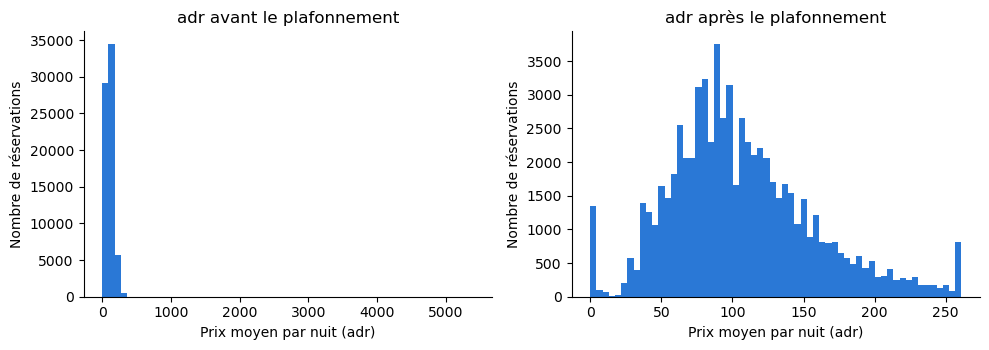

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].hist(X_train_cree["adr"], bins=60, color="#2a78d6")
axes[0].set_title("adr avant le plafonnement")

axes[1].hist(X_train_plafonne["adr"], bins=60, color="#2a78d6")
axes[1].set_title("adr après le plafonnement")

for ax in axes:
    ax.set_xlabel("Prix moyen par nuit (adr)")
    ax.set_ylabel("Nombre de réservations")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "03_plafonnement_adr.png", dpi=120)
plt.show()

**Ce qu'on observe :**

- **Avant :** à cause de quelques prix très élevés (jusqu'à 5 400), presque toutes les réservations sont collées à gauche. On ne voit pas la forme des données.
- **Après :** les prix vont de 0 à 261. On voit la vraie forme des prix : la plupart sont regroupés autour de la médiane (98,67, voir le tableau plus haut).
- On voit aussi deux petits pics :
    - à 0 (réservations gratuites) ;
    - à 261 (toutes les valeurs plafonnées).

## 4. Intégrer les transformateurs au pipeline de prétraitement

Ordre des étapes :
1. `CreationVariables` ajoute les 3 nouvelles colonnes ;
2. `PlafonnementValeurs` limite les valeurs extrêmes (aussi dans les nouvelles colonnes) ;
3. le `ColumnTransformer` du notebook 02 applique les traitements par type. On ajoute seulement les 3 nouvelles colonnes au groupe « num ».

In [9]:
# Groupe "num" du notebook 02 + les 3 nouvelles variables
groupe_num = groupes["num"] + CreationVariables.nouvelles_colonnes

preprocesseur = ColumnTransformer(
    transformers=[
        ("num_asym", pipelines["num_asym"], groupes["num_asym"]),
        ("num", pipelines["num"], groupe_num),
        ("bin", "passthrough", groupes["bin"]),
        ("cat_faible", pipelines["cat_faible"], groupes["cat_faible"]),
        ("cat_forte", pipelines["cat_forte"], groupes["cat_forte"]),
    ],
    remainder="drop",
)

pipeline_pretraitement = Pipeline([
    ("creation_variables", CreationVariables()),
    ("plafonnement", PlafonnementValeurs(colonnes=colonnes_a_plafonner, quantile=0.99)),
    ("colonnes", preprocesseur),
])

X_train_prep = pipeline_pretraitement.fit_transform(X_train)
X_test_prep = pipeline_pretraitement.transform(X_test)

print("X_train :", X_train.shape, "->", X_train_prep.shape)
print("X_test :", X_test.shape, "->", X_test_prep.shape)

X_train : (69783, 27) -> (69783, 108)
X_test : (17446, 27) -> (17446, 108)


**Ce qu'on observe :**

- Le pipeline complet transforme les 27 colonnes de départ en 108 colonnes.
- Au notebook 02, on avait 105 colonnes. Les 3 colonnes de plus sont nos nouvelles variables.

In [10]:
noms = pipeline_pretraitement.get_feature_names_out()
X_train_prep = pd.DataFrame(X_train_prep, columns=noms)

nouvelles = [n for n in noms if n.split("__")[1] in CreationVariables.nouvelles_colonnes]
print("Nouvelles colonnes dans la sortie du pipeline :", nouvelles)
print()
print(X_train_prep[nouvelles].agg(["mean", "std", "min", "max"]).round(2))

Nouvelles colonnes dans la sortie du pipeline : ['num__total_nuits', 'num__total_clients', 'num__prix_par_personne']

      num__total_nuits  num__total_clients  num__prix_par_personne
mean              0.00               -0.00                    0.00
std               1.00                1.00                    1.00
min              -1.42               -1.47                   -2.04
max               4.12                2.83                    3.49


**Ce qu'on observe :**

- Les 3 nouvelles variables sont bien dans la sortie, dans le groupe `num`.
- Elles sont plafonnées puis standardisées : moyenne 0 et écart-type 1.
- Leurs maximums restent modérés (entre 2,83 et 4,12). Sans le plafonnement, un prix par personne de 2 700 aurait donné une valeur énorme après la standardisation.

In [11]:
# Schéma du pipeline de prétraitement complet
pipeline_pretraitement

Pipeline(steps=[('creation_variables', CreationVariables()),
                ('plafonnement',
                 PlafonnementValeurs(colonnes=['adr', 'adults', 'children',
                                               'babies',
                                               'stays_in_weekend_nights',
                                               'stays_in_week_nights',
                                               'total_nuits', 'total_clients',
                                               'prix_par_personne'])),
                ('colonnes',
                 ColumnTransformer(transformers=[('num_asym',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='m...
                                                  ['hotel',
                                                   'arrival_date_month', 'meal',
                                                   'market_segment',
                                                   'distribution_channel',
                                                   'reserved_room_type',
                                                   'deposit_type',
                                                   'customer_type']),
                                                 ('cat_forte',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Inconnu',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.005,
                                                                                 sparse_output=False))]),
                                                  ['country', 'agent'])]))])

**Ce qu'on observe :**

- Le schéma montre les 3 étapes, dans l'ordre :
    1. `creation_variables` ;
    2. `plafonnement` ;
    3. `colonnes` (le ColumnTransformer du notebook 02).
- Quand on exécute la cellule dans VS Code, le schéma s'affiche aussi en blocs : on peut cliquer sur chaque bloc pour voir ses réglages.

## Sauvegarde pour le notebook 04

In [12]:
joblib.dump(pipeline_pretraitement, DOSSIER_MODELES / "etape3_pipeline_pretraitement.joblib")
print("Fichier créé : modeles/etape3_pipeline_pretraitement.joblib")

Fichier créé : modeles/etape3_pipeline_pretraitement.joblib


**Ce qu'on observe :**

- Le pipeline de prétraitement complet est sauvegardé.
- Le notebook 04 va le recharger et lui ajouter la sélection des caractéristiques.